Python для инженерии данных
## Домашнее задание 5
### Чанышев Тимур ВШЭ-ИД-1-26

### Задача 1

Реализуйте модель банковского счёта, которая не только меняет баланс, но и ведёт детальную историю действий.

Правила
- Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).
- Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.
- Поддерживаются операции пополнения и снятия: 
    1. Сумма операции должна быть положительной.
    2. Некорректная сумма приводит к исключению.
    3. При успехе баланс обновляется, в историю добавляется запись со статусом успешной операции.
    4. Если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции.
- Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.
- Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.

Демонстрация

В ноутбуке покажите:
- создание счёта;
- несколько успешных пополнений и снятий;
- хотя бы одну неуспешную попытку снятия;
- вывод баланса и истории.

In [3]:
import importlib

import matplotlib.pyplot as plt
import bank_accounts

importlib.reload(bank_accounts)
from bank_accounts import BankAccount

In [2]:
account = BankAccount("Тимур Чанышев", initial_balance=1000)
print("Владелец:", account.owner)
print("Номер счёта:", account.account_number)
print("Начальный баланс:", account.get_balance())

Владелец: Тимур Чанышев
Номер счёта: ACC-1000
Начальный баланс: 1000


Пополнения и снятия

In [3]:
account.deposit(1500)
account.deposit(500)
account.withdraw(700)
account.withdraw(400)
account.withdraw(5000)  # неуспешная попытка: на счёте недостаточно средств

Операция отклонена. Недостаточно средств на балансе: 1900


False

In [4]:
print("Текущий баланс:", account.get_balance())
account.get_history()

Текущий баланс: 1900


,operation,amount,datetime,balance_after,status
0,deposit,1500,2026-10-20 09:42:25,2500,success
1,deposit,500,2026-10-20 09:42:25,3000,success
2,withdraw,700,2026-10-20 09:42:25,2300,success
3,withdraw,400,2026-10-20 09:42:25,1900,success
4,withdraw,5000,2026-10-20 09:42:25,1900,fail


Проверка загрузки счёта из файла

In [5]:
loaded_account = BankAccount.load('ACC-1000')
print("Загруженный счёт:", loaded_account.account_number)
print("Сохранённый баланс:", loaded_account.get_balance())
loaded_account.get_history()

Загруженный счёт: ACC-1000
Сохранённый баланс: 1900


,operation,amount,datetime,balance_after,status
0,deposit,1500,2026-10-20 09:42:25,2500,success
1,deposit,500,2026-10-20 09:42:25,3000,success
2,withdraw,700,2026-10-20 09:42:25,2300,success
3,withdraw,400,2026-10-20 09:42:25,1900,success
4,withdraw,5000,2026-10-20 09:42:25,1900,fail


Линейный график изменения баланса во времени

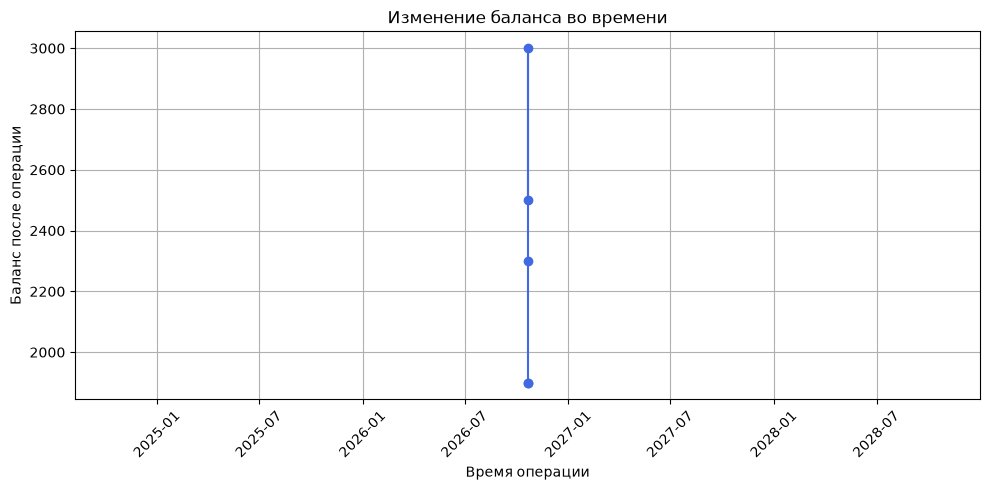

In [ ]:
# График странный из-за того что операции произошли в один момент...
history = loaded_account.get_history()

plt.figure(figsize=(10, 5))
plt.plot(
    history["datetime"],
    history["balance_after"],
    marker="o",
    color="royalblue",
)
plt.title("Изменение баланса во времени")
plt.xlabel("Время операции")
plt.ylabel("Баланс после операции")
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Задача 2

Расчётный и сберегательный счета должны отражать общее поведение учёта операций, но отличаться правилами.

Правила
- Расчётный счёт - базовые пополнение и снятие без дополнительных ограничений на долю снимаемой суммы.
- Сберегательный счёт: умеет начислять проценты на текущий остаток (ставку задаёт вызывающий код, например 7%); нельзя снять больше 50% текущего баланса; нарушающая правило попытка не меняет баланс и фиксируется в истории как неуспешная.
- У каждого типа счёта должен быть различимый тип (чтобы по объекту/данным было понятно, расчётный это счёт или сберегательный).
- Валидация имени владельца: формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. Для проверки используйте регулярные выражения.
- Аналитика по истории: возможность получить последние N крупных успешных операций (порог «крупности» и N задаёт вызывающий код).

Демонстрация. В ноутбуке покажите:
- создание расчётного и сберегательного счета;
- покажите начисление процентов на сберегательном;
- покажите отклонение снятия сверх 50% на сберегательном;
- покажите выборку последних крупных операций;
- покажите реакцию на некорректное имя владельца и/или некорректную сумму.

**Дополнительное задание. Перевод между счетами.**

Добавьте возможность перевода средств с одного счёта на другой:
- при успехе сумма списывается у отправителя и зачисляется получателю;
- если списание у отправителя невозможно (недостаточно средств или сработали ограничения сберегательного счёта), баланс получателя не меняется;
в историях обоих счетов перевод должен быть различим (например, общий идентификатор перевода, связанные записи или иной явный признак - способ выбираете вы).

In [10]:
# Для задания 2 решил расширить класс из задания 1.
# Существующий аккаунт сделал расчетным
import importlib
import bank_accounts

importlib.reload(bank_accounts)
from bank_accounts import BankAccount

Проверка некорректного имени владельца

In [ ]:
try:
    BankAccount("тимур чанышев", initial_balance=1000)
except ValueError as error:
    print("Ошибка:", error)

Ошибка: Имя должно быть в формате «Имя Фамилия»


In [11]:
checking_account = BankAccount("Иван Смирнов", initial_balance=10000, account_type="checking")
savings_account = BankAccount("Анна Дмитриевна", initial_balance=20000, account_type="savings")

print(checking_account.account_number, checking_account.account_type)
print(savings_account.account_number, savings_account.account_type)

ACC-1001 checking
ACC-1002 savings


Операции и начисление процентов

In [12]:
checking_account.deposit(8000)
checking_account.withdraw(2500)

interest = savings_account.add_interest(7)
print("Начисленные проценты:", interest)
print("Баланс сберегательного счёта:", savings_account.get_balance())

Начисленные проценты: 1400.0
Баланс сберегательного счёта: 21400.0


Отклонение снятия свыше 50% баланса

In [14]:
withdraw_result = savings_account.withdraw(12000)
print("Баланс после попытки:", savings_account.get_balance())
savings_account.get_history().tail(1)

Операция отклонена. Нельзя снять больше 50% баланса
Баланс после попытки: 21400.0


,operation,amount,datetime,balance_after,status,rate,reason
2,withdraw,12000.0,2026-10-20 10:18:57,21400.0,fail,NaN,exceeds_50_percent_limit


Последние крупные успешные операции

In [ ]:
checking_account.get_large_operations(min_amount=3000, n=3)

,operation,amount,datetime,balance_after,status,reason,transfer_id,related_account
0,deposit,8000,2026-10-20 10:18:26,18000,success,NaN,NaN,NaN
1,transfer_out,3000,2026-10-20 10:19:17,12500,success,NaN,3cc3bdba,ACC-1002


#### Дополнительное задание: перевод между счетами

In [15]:
transfer_id = checking_account.transfer_to(savings_account, 3000)
print("Успешный перевод:", transfer_id)
print("Баланс отправителя:", checking_account.get_balance())
print("Баланс получателя:", savings_account.get_balance())

receiver_balance_before = checking_account.get_balance()
failed_transfer = savings_account.transfer_to(checking_account, 15000)
print("Отклонённый перевод:", failed_transfer)
print("Баланс получателя не изменился:", checking_account.get_balance() == receiver_balance_before)

Успешный перевод: 3cc3bdba
Баланс отправителя: 12500
Баланс получателя: 24400.0
Отклонённый перевод: None
Баланс получателя не изменился: True


In [16]:
checking_account.get_history().tail(1)

,operation,amount,datetime,balance_after,status,reason,transfer_id,related_account
2,transfer_out,3000,2026-10-20 10:19:17,12500,success,NaN,3cc3bdba,ACC-1002


In [17]:
savings_account.get_history().tail(2)

,operation,amount,datetime,balance_after,status,rate,reason,transfer_id,related_account
3,transfer_in,3000.0,2026-10-20 10:19:17,24400.0,success,NaN,NaN,3cc3bdba,ACC-1001
4,transfer_out,15000.0,2026-10-20 10:19:17,24400.0,fail,NaN,exceeds_50_percent_limit,f46112e4,ACC-1001


### Задача 3

Перед началом работы загрузите из личного кабинета файлы transactions_dirty.csv и transactions_dirty.json.
Файл общий для нескольких счетов: нужно загружать в конкретный счёт только его операции (фильтрация по номеру счёта / типу - по данным файла).
Правила
- Реализуйте загрузку истории из CSV и\или из JSON.
- Перед записью в историю отбрасывайте невалидные строки: опечатки в типе операции, пустые или отрицательные суммы, некорректные даты, некорректный статус и т.п.
- Для сберегательного счёта допустимы типы операций deposit, withdraw, interest; для расчётного - только deposit и withdraw. Операции, недопустимые для типа счёта, невалидны.
- После успешной загрузки валидных операций баланс счёта должен соответствовать последовательности принятых операций.

Демонстрация. Загрузите данные хотя бы из одного формата в расчётный и в сберегательный счёт, покажите обновлённый баланс и фрагмент истории.

**Дополнительное задание. Отчёт об отбраковке**

Помимо «молчаливого» отбрасывания мусора сформируйте явный результат очистки:
- сколько строк принято,
- сколько отклонено,
- почему отклонена каждая (или группа) строк - битая дата, пустая сумма, опечатка в типе (diposit), interest на расчётном счёте, неверный статус и тд.

Формат отчёта на ваш выбор (список, датафрейм, печать сводки) - главное, чтобы его можно было показать в ноутбуке и по нему было понятно, что произошло с данными.

In [22]:
# Для задания 3 также расширяю класс из задания 1.

import importlib
import bank_accounts

importlib.reload(bank_accounts)
from bank_accounts import BankAccount

Загрузка данных из CSV

In [23]:
# Начальные балансы счетов до первой операции в исходном файле
checking_import_account = BankAccount("Петр Иванов", initial_balance=1200, account_type="checking")
savings_import_account = BankAccount("Мария Петрова", initial_balance=1500, account_type="savings")

In [24]:
file_path = "../src/transactions_dirty.csv"

checking_report = checking_import_account.load_operations(file_path, "ACC-100001")
savings_report = savings_import_account.load_operations(file_path, "ACC-100002")

Результат загрузки в расчётный счёт

In [25]:
print("Принято строк:", checking_report["accepted"])
print("Отклонено строк:", checking_report["rejected"])
print("Пропущено строк других счетов:", checking_report["skipped_other_accounts"])
print("Обновлённый баланс:", checking_import_account.get_balance())
checking_import_account.get_history().tail()

Принято строк: 18
Отклонено строк: 8
Пропущено строк других счетов: 79
Обновлённый баланс: 4471.0


,operation,amount,datetime,balance_after,status,source_account_number
13,withdraw,393.0,2025-10-16 22:17:26,4336.0,success,ACC-100001
14,deposit,701.0,2025-10-16 22:17:26,5037.0,success,ACC-100001
15,withdraw,308.0,2025-10-17 22:17:26,4729.0,success,ACC-100001
16,deposit,135.0,2025-10-18 22:17:26,4864.0,success,ACC-100001
17,withdraw,393.0,2025-10-16 22:17:26,4471.0,success,ACC-100001


In [26]:
checking_report["rejected_rows"]

,row_index,operation,amount,date,status,reason
0,5,withdraw,NaN,2025-09-29 22:17:26,success,пустая или некорректная сумма
1,8,NaN,654.0,2025-10-01 22:17:26,success,пустой тип операции
2,10,interest,532.0,2025-10-03 22:17:26,success,операция interest недопустима для checking
3,13,deposit,793.0,2025-17-34 12:00:00,success,некорректная дата
4,15,diposit,669.0,2025-10-06 22:17:26,success,неизвестная операция: diposit
5,16,interest,744.0,2025-10-08 22:17:26,success,операция interest недопустима для checking
6,17,withdraw,111.0,2023-16-40 12:00:00,success,некорректная дата
7,24,deposit,916.0,2025-10-19 22:17:26,succes,некорректный статус: succes


Результат загрузки в сберегательный счёт

In [27]:
print("Принято строк:", savings_report["accepted"])
print("Отклонено строк:", savings_report["rejected"])
print("Пропущено строк других счетов:", savings_report["skipped_other_accounts"])
print("Обновлённый баланс:", savings_import_account.get_balance())
savings_import_account.get_history().tail()

Принято строк: 19
Отклонено строк: 8
Пропущено строк других счетов: 78
Обновлённый баланс: 4629.24


,operation,amount,datetime,balance_after,status,source_account_number
14,interest,274.13,2025-10-15 22:17:26,4257.11,success,ACC-100002
15,withdraw,286.00,2025-10-17 22:17:26,3971.11,success,ACC-100002
16,interest,302.13,2025-10-20 22:17:26,4273.24,success,ACC-100002
17,withdraw,282.00,2025-10-23 22:17:26,3991.24,success,ACC-100002
18,deposit,638.00,2025-10-09 22:17:00,4629.24,success,ACC-100002


In [28]:
savings_report["rejected_rows"]

,row_index,operation,amount,date,status,reason
0,28,deposit,797.0,2023-22-32 12:00:00,success,некорректная дата
1,29,interest,NaN,2025-09-30 22:17:26,success,пустая или некорректная сумма
2,33,deposit,-136.0,2025-10-08 22:17:26,success,сумма должна быть положительной
3,37,diposit,432.0,2025-10-09 22:17:26,success,неизвестная операция: diposit
4,44,deposit,-872.0,2025-10-16 22:17:26,success,сумма должна быть положительной
5,46,withdraw,300.0,2025-10-19 22:17:26,succes,некорректный статус: succes
6,48,wdraw,457.0,2025-10-22 22:17:26,success,неизвестная операция: wdraw
7,103,withdraw,300.0,2025-10-19 22:17:26,succes,некорректный статус: succes
